In [79]:
## 1.grid search cv

## 2.avoid overfitting low bais +igh variance

## 1. Business Understanding   - The person will come with attroney or not to claim the insurance

## Import Neccessary Libraries

In [1]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings(action="ignore")

# 2. Data Collection

# import dataset

In [2]:
cliamants_data = pd.read_csv("cliamants.csv")
cliamants_data

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,5,0,0.0,1.0,0.0,50.0,34.940
1,3,1,1.0,0.0,0.0,18.0,0.891
2,66,1,0.0,1.0,0.0,5.0,0.330
3,70,0,0.0,1.0,1.0,31.0,0.037
4,96,1,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...,...,...
1335,34100,1,0.0,1.0,0.0,NaN,0.576
1336,34110,0,1.0,1.0,0.0,46.0,3.705
1337,34113,1,1.0,1.0,0.0,39.0,0.099
1338,34145,0,1.0,0.0,0.0,8.0,3.177


## 3. Data Understanding

In [3]:
cliamants_data.shape

(1340, 7)

In [4]:
cliamants_data.columns

Index(['CASENUM', 'ATTORNEY', 'CLMSEX', 'CLMINSUR', 'SEATBELT', 'CLMAGE',
       'LOSS'],
      dtype='object')

In [5]:
cliamants_data.isnull().sum()

CASENUM       0
ATTORNEY      0
CLMSEX       12
CLMINSUR     41
SEATBELT     48
CLMAGE      189
LOSS          0
dtype: int64

## 4. Data Preparation

## 4.1 Data cleaning

In [6]:
cliamants_data.dropna(inplace=True)

In [7]:
cliamants_data.isnull().sum()

CASENUM     0
ATTORNEY    0
CLMSEX      0
CLMINSUR    0
SEATBELT    0
CLMAGE      0
LOSS        0
dtype: int64

## 4.2 Seperate Input and output

In [8]:
X = cliamants_data[['CLMSEX', 'CLMINSUR', 'SEATBELT', 'CLMAGE','LOSS']]
X


,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,0.0,1.0,0.0,50.0,34.940
1,1.0,0.0,0.0,18.0,0.891
2,0.0,1.0,0.0,5.0,0.330
3,0.0,1.0,1.0,31.0,0.037
4,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...
1334,1.0,1.0,0.0,16.0,0.060
1336,1.0,1.0,0.0,46.0,3.705
1337,1.0,1.0,0.0,39.0,0.099
1338,1.0,0.0,0.0,8.0,3.177


In [9]:
y = cliamants_data['ATTORNEY']
y

0       0
1       1
2       1
3       0
4       1
       ..
1334    1
1336    0
1337    1
1338    0
1339    1
Name: ATTORNEY, Length: 1096, dtype: int64

## 5. Model Building

## 5.1 Split the data into Train and Test

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state= 32,shuffle=True)


## X_train,y_train  -- training data
## X_test,y_test  --- testing data

In [11]:
X_train

,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
963,1.0,1.0,0.0,6.0,0.608
615,1.0,1.0,0.0,0.0,0.407
74,0.0,1.0,0.0,0.0,0.445
543,0.0,1.0,0.0,44.0,3.666
287,1.0,1.0,0.0,19.0,68.560
...,...,...,...,...,...
625,1.0,1.0,0.0,71.0,8.708
305,0.0,1.0,0.0,33.0,0.886
107,1.0,0.0,0.0,10.0,3.975
1091,0.0,0.0,0.0,47.0,6.070


In [12]:
X_test

,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
1035,0.0,1.0,0.0,10.0,0.663
1255,0.0,1.0,0.0,48.0,0.455
347,1.0,1.0,0.0,56.0,3.009
121,1.0,1.0,0.0,9.0,5.813
511,1.0,1.0,0.0,8.0,3.086
...,...,...,...,...,...
354,1.0,0.0,0.0,13.0,3.091
981,0.0,1.0,0.0,1.0,0.100
178,1.0,1.0,0.0,4.0,4.117
262,0.0,0.0,0.0,6.0,0.598


In [13]:
## calling the model 

logistic_model = LogisticRegression()

## 6. Model Training

## 6.1 Logistic model fit

In [14]:
logistic_model.fit(X_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


## 6.2 Decision Tree

In [15]:
from sklearn.tree import DecisionTreeClassifier

# calling the decision tree model

## To resolve overfitting we are using max_depth(means the tree will grow until particular depth to leaf node) 

## Grid search CV(CROSS VALIDATION)

**It is used for hyperparameter tuning to find optimal values for the model (i:e:- max_depth=5,criteria="entropy"). By this we can fit the decision tree and train,test the model to get good performance model.**

In [63]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(estimator=dt_model,param_grid={"max_depth":[4,5,6,7,8,9,10], "criterion":["gini","entropy"]})

grid_search.fit(X,y)

print(grid_search.best_params_)
print(grid_search.best_score_)

{'criterion': 'gini', 'max_depth': 4}
0.7290037359900374


In [49]:
# TO SEE THE DECISION TREE
from sklearn.tree import DecisionTreeClassifier,plot_tree

In [64]:
dt_model = DecisionTreeClassifier(max_depth= 4,criterion="gini")  

## Fit the decision tree

In [65]:
dt_model.fit(X_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


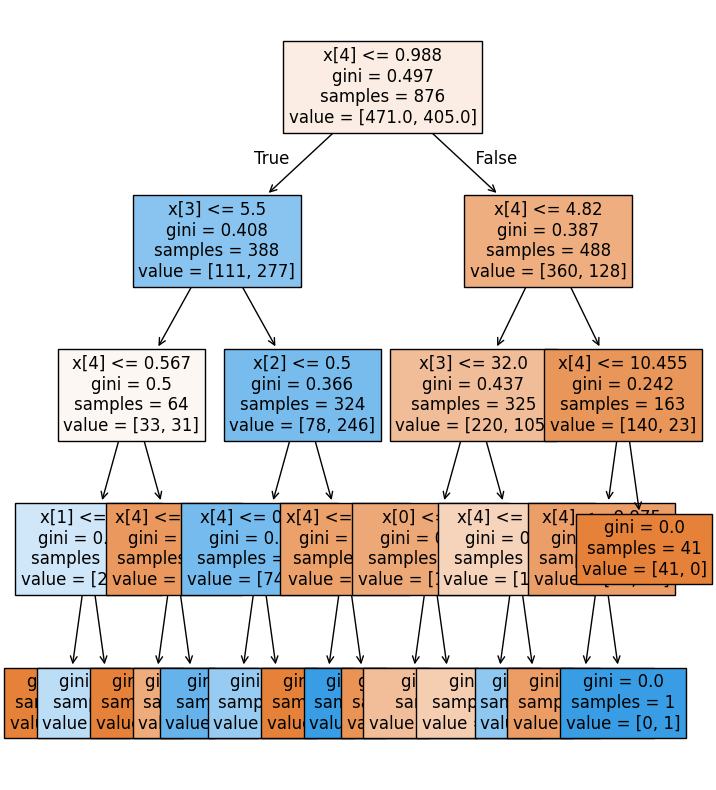

In [66]:
plt.figure(figsize=(8,10))
plot_tree(decision_tree=dt_model,fontsize=12,filled=True)
plt.show()

 ## 7. Model Testing

## Predict training output for decision tree

In [69]:
y_pred_train = dt_model.predict(X_train)
y_pred_train

array([1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1,
       0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0,
       0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1,
       1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1,
       0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0,
       0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1,
       0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1,
       1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0,
       0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1,

## Predict testing output for decision tree

In [70]:
y_pred_test = dt_model.predict(X_test)
y_pred_test

array([1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0,
       0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1,
       1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1,
       0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0,
       0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0,
       1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0,
       0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1])

## 8. Model Evaluation

In [71]:
from sklearn.metrics import accuracy_score,auc,classification_report,confusion_matrix,roc_curve,roc_auc_score

## 8.1 Training Data's evaluation metrics

## confusion metrics

## here confusion matrix changes because we stopping till 5 depth of leaf node

In [72]:
print(confusion_matrix(y_train,y_pred_train))

[[375  96]
 [122 283]]


In [73]:
print(classification_report(y_train,y_pred_train))

              precision    recall  f1-score   support

           0       0.75      0.80      0.77       471
           1       0.75      0.70      0.72       405

    accuracy                           0.75       876
   macro avg       0.75      0.75      0.75       876
weighted avg       0.75      0.75      0.75       876



## ROC curve

## AUC curve 

## for training data

## here it is 74%


0.7474718880239051


Text(0, 0.5, 'True Positive Rate')

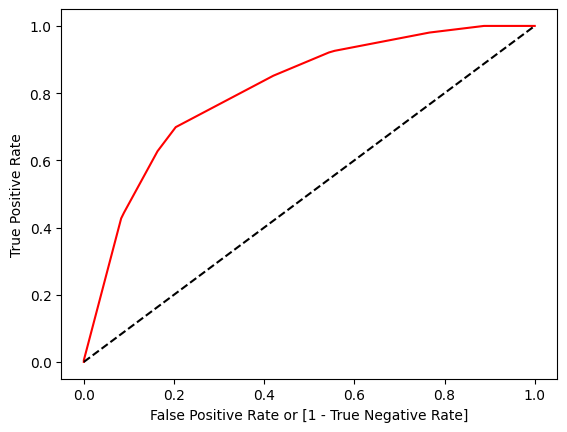

In [74]:
fpr, tpr, thresholds = roc_curve(y_train, dt_model.predict_proba (X_train)[:,1])

auc = roc_auc_score(y_train,y_pred_train)
print(auc)

import matplotlib.pyplot as plt
plt.plot(fpr, tpr, color='red', label='logit model ( area  = %0.2f)'%auc)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate or [1 - True Negative Rate]')
plt.ylabel('True Positive Rate')

## below accuracy for unseen data y_test

In [75]:
accuracy_score(y_test,y_pred_test)

0.7363636363636363

In [76]:
print(confusion_matrix(y_test,y_pred_test))

[[82 25]
 [33 80]]


In [77]:
print(classification_report(y_test,y_pred_test))

              precision    recall  f1-score   support

           0       0.71      0.77      0.74       107
           1       0.76      0.71      0.73       113

    accuracy                           0.74       220
   macro avg       0.74      0.74      0.74       220
weighted avg       0.74      0.74      0.74       220



## ROC curve

## AUC curve

## for testing data

## here it is 73%

0.7371598709784137


Text(0, 0.5, 'True Positive Rate')

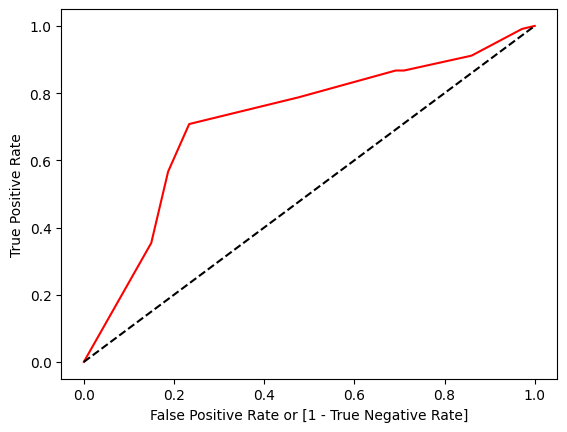

In [78]:
fpr, tpr, thresholds = roc_curve(y_test, dt_model.predict_proba (X_test)[:,1])

auc = roc_auc_score(y_test,y_pred_test)
print(auc)

import matplotlib.pyplot as plt
plt.plot(fpr, tpr, color='red', label='logit model ( area  = %0.2f)'%auc)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate or [1 - True Negative Rate]')
plt.ylabel('True Positive Rate')

## After resolving the overfitting of decision tree, our training roc is 74% and testing roc is 73% . more or less equal percentage 
## Now our Model is  GENERALIZED MODEL



## Bias variance

**Bias - always associated with Training data**


**variance - always associated with Testing data**

## LOW BIAS + HIGH VARIANCE = OVERFITTING

## HIGH BIAS + LOW VARIANCE = UNDERFITTING

## LOW BIAS + LOW VARIANCE = GENERALISED MODEL  ---> WE NEED THIS MODEL ONLY

## sO THERE IS ALWAYS TRADEOFF BETWEEN BIAS AND VARIANCE

